<a href="https://colab.research.google.com/github/mipaillafil/proyecto-telco-churn/blob/main/ev_2_mch_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Proyecto Machine Learning: Predicción de abandono de clientes (Telco Customer Churn)**

**Integrantes:** Kimberly Bobadilla, Luna Cortés y Millaray Paillafil.

**Problema de negocio:** una empresa de telecomunicaciones pierde ingresos cuando un cliente se va (*churn*). Retener a un cliente cuesta menos que conseguir uno nuevo, por eso queremos **predecir quiénes tienen más probabilidad de irse** y así enfocar las ofertas de retención.

**Objetivos**
1. Analizar qué características tienen los clientes que abandonan (EDA).
2. Construir y comparar 3 modelos supervisados de clasificación.
3. Agrupar a los clientes con un modelo no supervisado (K-Means).
4. Evaluar con métricas adecuadas y dar recomendaciones al negocio.
5. Revisar el impacto ético del modelo.

**Metodología:** CRISP-DM adaptado → comprensión del negocio → comprensión de datos → preparación → modelado → evaluación → recomendaciones. El desarrollo detallado y las justificaciones están en el informe técnico.

##**1. Librerías y Carga de Datos**

In [95]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, silhouette_score,
                             davies_bouldin_score, adjusted_rand_score)

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
RANDOM_STATE = 42

In [96]:
# Crea el directorio para guardar imágenes si no existe
os.makedirs('images', exist_ok=True)

# Crea el directorio para guardar modelos si no existe
os.makedirs('models', exist_ok=True)

def guardar(nombre):
    # Guarda el gráfico actual como PNG en la carpeta 'images' con buena resolución y sin bordes sobrantes
    plt.savefig(f'images/{nombre}.png', dpi=150, bbox_inches='tight')

In [97]:
df = pd.read_csv('/content/data/Telco_Customer_Churn_Clean.csv')
df.head(3)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


**Fuente de datos:** Telco Customer Churn (IBM), 7.043 clientes y 20 variables (demográficas, servicios contratados, contrato, facturación y la variable objetivo `Churn`). Se usa una versión limpia, guardada en `data/`. El dataset no incluye identificador de cliente.

##**2. Calidad de los Datos**
Se revisó el tamaño, los tipos de datos, los nulos, los duplicados y los estadísticos de las variables numéricas.



In [98]:
#Ver cantidad de filas y columnas del dataset
print("Filas y columnas: ", df.shape)

Filas y columnas:  (7043, 20)


In [99]:
#Ver tipos de datos
print('Tipos de datos:')
print(df.dtypes)

Tipos de datos:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [100]:
#Ver cantidad de valores nulos
print('Total de valores nulos:', df.isnull().sum().sum())

Total de valores nulos: 0


In [101]:
#Ver cantidad de valores duplicados
n_dup = df.duplicated().sum()
print('Total de valores duplicados:', n_dup)

Total de valores duplicados: 22


**Duplicados:** se detectaron 22 filas repetidas (0,3 %). Sin embargo, podemos asegurar que son clientes distintos, ya que nosotras fuimos las que limpiamos el dataset en la evaluación anterior.

In [102]:
#Ver datos estadisticos
print('Estadísticos de las variables numéricas:')
print(df.describe().round(2))

Estadísticos de las variables numéricas:
       SeniorCitizen   tenure  MonthlyCharges  TotalCharges
count        7043.00  7043.00         7043.00       7043.00
mean            0.16    32.37           64.76       2279.73
std             0.37    24.56           30.09       2266.79
min             0.00     0.00           18.25          0.00
25%             0.00     9.00           35.50        398.55
50%             0.00    29.00           70.35       1394.55
75%             0.00    55.00           89.85       3786.60
max             1.00    72.00          118.75       8684.80


**Nota:** `TotalCharges = 0` corresponde a **11** clientes con `tenure = 0` (clientes nuevos sin primera facturación). Se conservan porque son registros válidos.

##**3. EDA: Variable Objetivo (Churn)**
Se cuenta cuantos clientes se van y cuantos se quedan. Con la finalidad, de saber si las clases están balanceadas.

In [103]:
#Transforma 'No'/'Yes' a 0/1 y crea la columna 'Churn_num'
df['Churn_num'] = df['Churn'].map({'No': 0, 'Yes': 1})

#Cantidad total de 'No' y 'Yes'
print(df['Churn'].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [104]:
#Cantidad total de 'No' y 'Yes' en porcentaje
print((df['Churn'].value_counts(normalize=True) * 100).round(1))

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


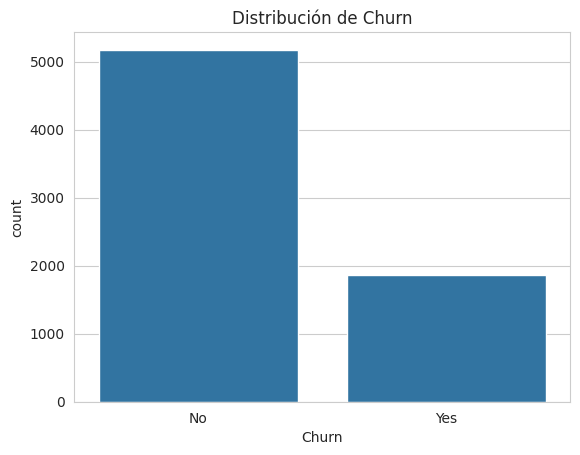

In [105]:
#Distribución visual de Churn
sns.countplot(x='Churn', data=df)
plt.title('Distribución de Churn')
guardar('distribucion_churn')
plt.show()

##**4. EDA: Variables numéricas**

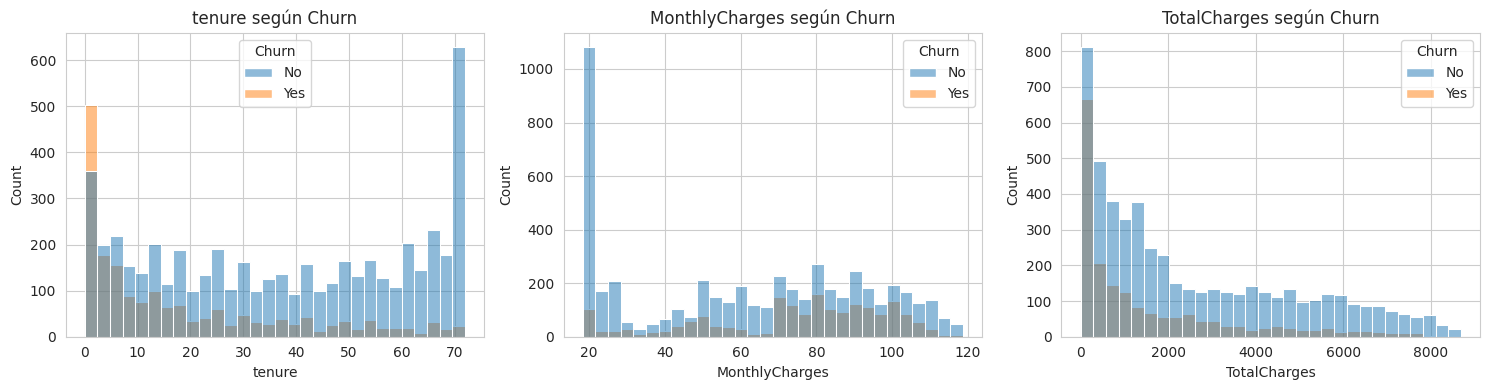

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       37.6            61.3        2549.9
Yes      18.0            74.4        1531.8


In [106]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.histplot(data=df, x=col, hue='Churn', bins=30, ax=axes[i])
    axes[i].set_title(col + ' según Churn')
plt.tight_layout()
guardar('variables_numericas_churn')
plt.show()

print(df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean().round(1))

**Análisis:** los clientes que abandonan tienen en promedio 18,0 meses de antigüedad contra 37,6 de los que se quedan, y pagan más al mes (74,4 contra 61,3). Su TotalCharges es menor (1.532 contra 2.550) simplemente porque llevan menos tiempo. Los clientes antiguos casi no se van.

##**5. EDA: Variables categóricas**

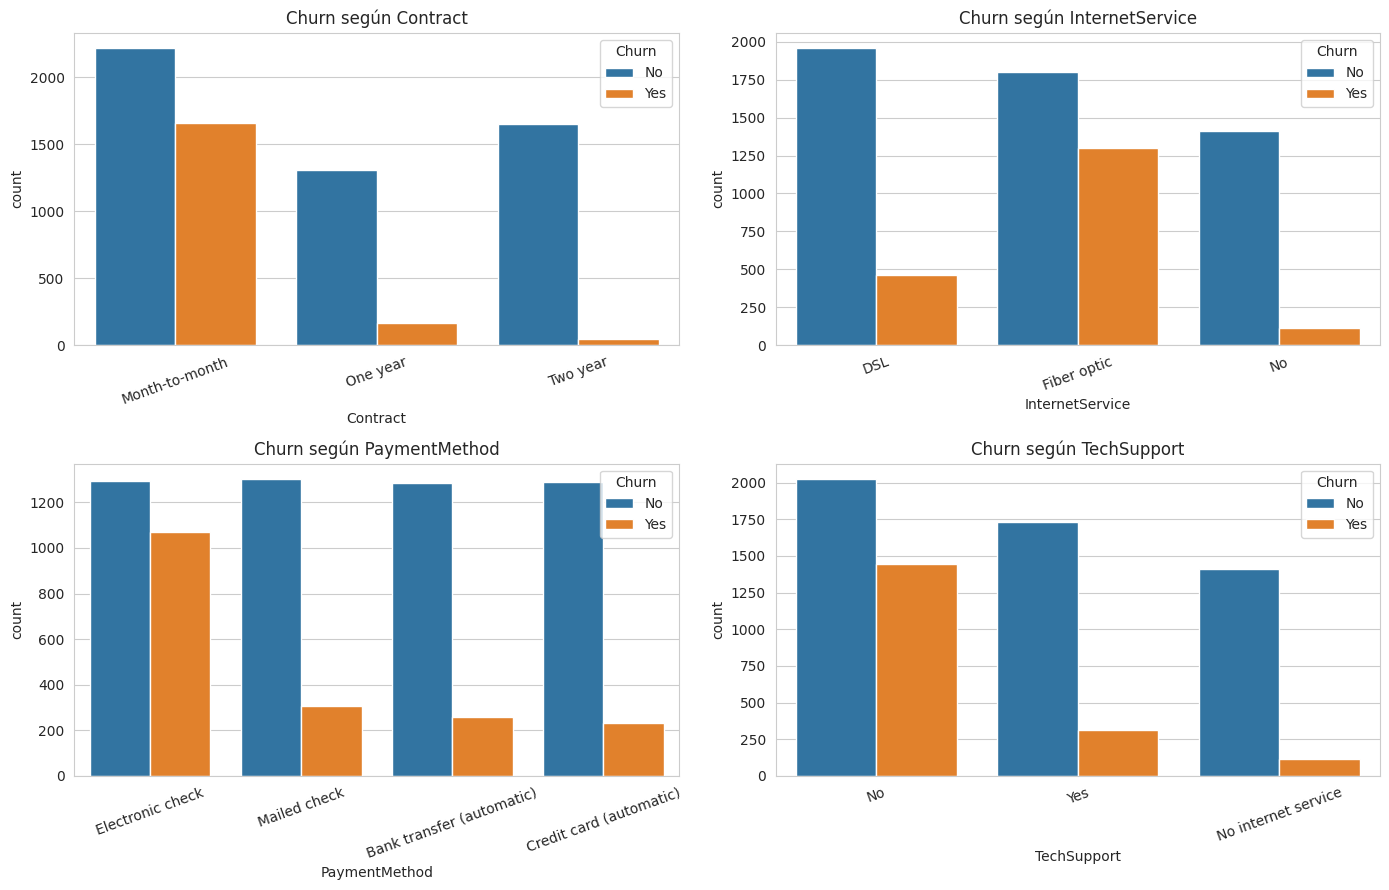

In [107]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flatten(), ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']):
    sns.countplot(x=col, hue='Churn', data=df, ax=ax)
    ax.set_title('Churn según ' + col)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
guardar('variables_categoricas_churn')
plt.show()

In [108]:
#Porcentaje de churn por categoría (incluye gender y SeniorCitizen, que se usan en la revisión ética)
for col in ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport', 'SeniorCitizen', 'gender']:
    print((df.groupby(col)['Churn_num'].mean() * 100).round(1).to_string(), '\n')

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8 

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4 

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1 

TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2 

SeniorCitizen
0    23.6
1    41.7 

gender
Female    26.9
Male      26.2 



**Análisis:**

*  **Contrato:** 42,7 % de churn con contrato mes a mes, 11,3 % con 1 año y 2,8 % con 2 años.
*  **Internet:** 41,9 % con fibra óptica, 19,0 % con DSL y 7,4 % sin internet.
*  **Pago:** 45,3 % con cheque electrónico, contra 15,2 % a 19,1 % en los otros métodos.
*  **Soporte técnico:** 41,6 % sin soporte, 15,2 % con soporte.
*  **Adultos mayores:** 41,7 % de churn contra 23,6 % en el resto.
*  **Género:** 26,9 % en mujeres y 26,2 % en hombres, es decir, no hay diferencia relevante.

##**6. EDA: Correlaciones**

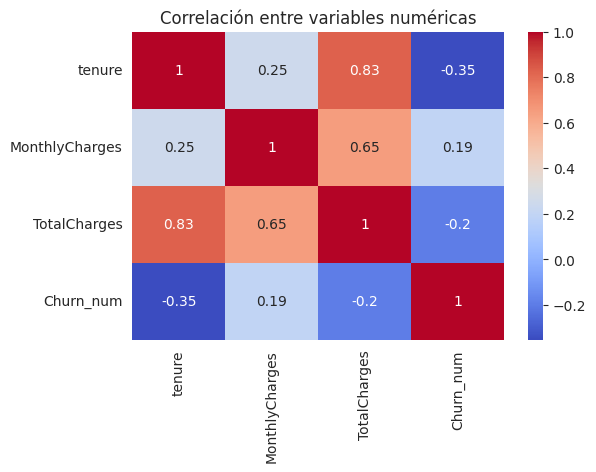

In [109]:
plt.figure(figsize=(6, 4))
sns.heatmap(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_num']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlación entre variables numéricas')
guardar('matriz_correlacion')
plt.show()

**Analisis de correlaciones:**

El mapa de calor revela que la antigüedad (tenure) es el factor más determinante para la retención, mostrando una correlación negativa moderada con el churn (-0.35) que indica que los clientes nuevos son más propensos a irse, mientras que los cargos mensuales (MonthlyCharges) presentan una ligera relación positiva con el abandono (0.19); asimismo, destaca la alta multicolinealidad entre TotalCharges y tenure (0.83), sugiriendo evaluar la eliminación de la primera para no distorsionar el rendimiento de ciertos modelos predictivos.

##**7. Preparación de los Datos**


In [110]:
#Variable objetivo y variables predictoras (gender se excluye por ética)
y = df['Churn_num']
X = pd.get_dummies(df.drop(columns=['gender', 'Churn', 'Churn_num']), drop_first=True).astype(float)

print('Dimensión final de X:', X.shape)
print(list(X.columns))

Dimensión final de X: (7043, 29)
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


##**8. División de Train/Test**
Separar el dataset en 80% de datos para entrenamiento y 20% para testing. Implementando stratify=y para mantener la misma proporción de churn en ambos.

In [111]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Tamaño Train:', X_train.shape, '| Tamaño Test:', X_test.shape)
print('% churn en train:', round(y_train.mean() * 100, 1), '| % churn en test:', round(y_test.mean() * 100, 1))

Tamaño Train: (5634, 29) | Tamaño Test: (1409, 29)
% churn en train: 26.5 | % churn en test: 26.5


##**9. Modelos Supervisados**
Se entrenan tres clasificadores: Regresión Logística, Random Forest y Gradient Boosting. Los tres usan los mismos 5 folds estratificados, hiperparámetros ajustados con `GridSearchCV` (ROC-AUC) y manejo del desbalance de clases. Como referencia se incluye un Gradient Boosting sin balancear.

**Selección de modelos:** Regresión Logística como línea base interpretable, Random Forest por su capacidad de capturar no linealidades e interacciones, y Gradient Boosting por su buen rendimiento en datos tabulares. Se excluye `TotalCharges` de la Regresión Logística por su alta correlación con `tenure` (0,83).

In [112]:
#Misma validación cruzada (5 folds estratificados) para todos los modelos
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

#Variables de cada modelo
COLS_ARBOLES = list(X.columns)
COLS_LR = [c for c in X.columns if c != 'TotalCharges'] #Se excluye TotalCharges por su colinealidad alta con tenure

###**Modelo 1: Regresión Logistica**

In [113]:
lr_grid = GridSearchCV(
    make_pipeline(StandardScaler(),
                  LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
    {'logisticregression__C': [0.01, 0.1, 1, 10]},
    cv=cv, scoring='roc_auc', n_jobs=-1)
lr_grid.fit(X_train[COLS_LR], y_train)
lr = lr_grid.best_estimator_
print('LR -> mejor C:', lr_grid.best_params_, '| AUC CV:', round(lr_grid.best_score_, 3))

LR -> mejor C: {'logisticregression__C': 10} | AUC CV: 0.845


Se ajusta el parámetro de regularización C con validación cruzada. Mejor valor: 10 | AUC CV: 0.845

###**Modelo 2: Random Forest**

In [114]:
# Configura la búsqueda por malla (GridSearchCV) para optimizar hiperparámetros de RandomForest con validación cruzada y métrica ROC-AUC
rf_grid = GridSearchCV(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
                       {'n_estimators': [100, 200], 'max_depth': [5, 8, 12], 'min_samples_leaf': [1, 5, 10]},
                       cv=cv, scoring='roc_auc', n_jobs=-1)

# Entrena la búsqueda en la malla sobre los datos de entrenamiento probando todas las combinaciones posibles
rf_grid.fit(X_train[COLS_ARBOLES], y_train)

# Extrae e instancia el modelo óptimo obtenido con la mejor combinación de hiperparámetros
rf = rf_grid.best_estimator_
print('Random Forest      -> mejores parámetros:', rf_grid.best_params_, '| AUC CV:', round(rf_grid.best_score_, 3))

Random Forest      -> mejores parámetros: {'max_depth': 8, 'min_samples_leaf': 10, 'n_estimators': 200} | AUC CV: 0.848


###**Modelo 3: Gradient Boosting**

In [115]:
# Calcula los pesos de cada muestra para compensar el desbalance de clases en los datos de entrenamiento
sw_train = compute_sample_weight(class_weight='balanced', y=y_train)

# Configura la búsqueda por malla (GridSearchCV) para ajustar los hiperparámetros de GradientBoosting usando ROC-AUC
gb_grid = GridSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE),
                       {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [2, 3]},
                       cv=cv, scoring='roc_auc', n_jobs=-1)

# Entrena el modelo probando las combinaciones de la malla sobre las características seleccionadas y aplicando los pesos de muestra
gb_grid.fit(X_train[COLS_ARBOLES], y_train, sample_weight=sw_train)

# Guarda en la variable 'gb' el mejor modelo obtenido con la combinación óptima de hiperparámetros
gb = gb_grid.best_estimator_

# Referencia: mismo Gradient Boosting SIN balancear (solo para mostrar el efecto del balanceo)
gb_ref = clone(gb).fit(X_train[COLS_ARBOLES], y_train)

print('Gradient Boosting  -> mejores parámetros:', gb_grid.best_params_, '| AUC CV:', round(gb_grid.best_score_, 3))

Gradient Boosting  -> mejores parámetros: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200} | AUC CV: 0.849


###**Variables Finales por Modelo**

| Modelo | N° Variables | Variable excluida | Escalado | Tratamiento del desbalance |
|---|---|---|---|---|
| Regresión Logística | 28 | TotalCharges (colinealidad con tenure) | StandardScaler (en pipeline) | class_weight='balanced' |
| Random Forest | 29 | ninguna | no necesita | class_weight='balanced' |
| Gradient Boosting | 29 | ninguna | no necesita | sample_weight balanceado |



In [116]:
print('Variables de la Regresión Logística:')
print(COLS_LR)
print('\nVariables de Random Forest y Gradient Boosting (las mismas):')
print(COLS_ARBOLES)

Variables de la Regresión Logística:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']

Variables de Random Forest y Gradient Boosting (las mismas):
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'In

##**10. Comparación y Selección del Modelo**

In [117]:
#Definir un diccionario estructurado que almacena cada modelo, sus variables asignadas y sus parámetros de entrenamiento
modelos = {
    'Regresión Logística':            dict(est=lr, cols=COLS_LR,       fit_params=None),
    'Random Forest':                  dict(est=rf, cols=COLS_ARBOLES,  fit_params=None),
    'Gradient Boosting (balanceado)': dict(est=gb, cols=COLS_ARBOLES,  fit_params={'sample_weight': sw_train}),
}


#Inicializar un diccionario vacío para guardar las predicciones fuera de fold de cada modelo
oof = {}

#Recorrer cada modelo del diccionario para generar sus predicciones probabilísticas mediante validación cruzada (sin fuga de datos)
for nombre, m in modelos.items():
    oof[nombre] = cross_val_predict(clone(m['est']), X_train[m['cols']], y_train, cv=cv,
                                    method='predict_proba', params=m['fit_params'])[:, 1]

#Construir un DataFrame comparativo con las métricas ROC-AUC y Average Precision redondeadas a 3 decimales para cada modelo
tabla_cv = pd.DataFrame({
    'Modelo': list(oof.keys()),
    'ROC-AUC (CV)': [roc_auc_score(y_train, p) for p in oof.values()],
    'Average Precision (CV)': [average_precision_score(y_train, p) for p in oof.values()],
}).round(3)

tabla_cv

,Modelo,ROC-AUC (CV),Average Precision (CV)
0,Regresión Logística,0.845,0.655
1,Random Forest,0.847,0.661
2,Gradient Boosting (balanceado),0.848,0.663


Los tres modelos obtienen un ROC-AUC en validación cruzada prácticamente igual (entre 0.845 y 0.848); la diferencia está dentro del ruido del CV. Se selecciona **Gradient Boosting (balanceado)** por tener el mayor desempeño global en validación cruzada (tanto en ROC-AUC de 0.848 como en Average Precision de 0.663) y su consistencia para manejar datos tabulares complejos con balanceo de muestras.

##**11. Evaluación Final en el Conjunto de Prueba**
Se evaluó el rendimiento final de los modelos en el conjunto de prueba (test) utilizando un umbral estándar de 0.5 para garantizar una comparación equitativa, además de optimizar dicho umbral para el modelo definitivo; para ello, se analizaron sus matrices de confusión, curvas ROC y Precision-Recall, y se estimó el impacto económico de las retenciones considerando diversos niveles de efectividad en las ofertas aplicadas.

In [118]:
# Estandarizamos los nombres de las llaves de modelos a minúsculas para evitar discrepancias
probs_test = {n.lower(): m['est'].predict_proba(X_test[m['cols']])[:, 1] for n, m in modelos.items()}

# Añadimos el modelo de referencia
probs_test['gradient boosting (sin balancear, referencia)'] = gb_ref.predict_proba(X_test[COLS_ARBOLES])[:, 1]

# Definimos una función para calcular el conjunto de métricas de clasificación según un umbral de decisión específico
def metricas(nombre, prob, umbral):
    pred = (prob >= umbral).astype(int)
    return {'Modelo': nombre, 'Umbral': umbral,
            'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred),
            'ROC_AUC': roc_auc_score(y_test, prob)}

# Generamos una lista con las métricas de todos los modelos evaluados en el conjunto de test usando un umbral estándar de 0.5
filas = [metricas(n.title(), p, 0.5) for n, p in probs_test.items()]

# Convierte la lista de resultados en un DataFrame comparativo y redondea los valores a 3 decimales
tabla_test = pd.DataFrame(filas).round(3)
display(tabla_test)

,Modelo,Umbral,Accuracy,Precision,Recall,F1,ROC_AUC
0,Regresión Logística,0.5,0.742,0.509,0.775,0.614,0.838
1,Random Forest,0.5,0.754,0.525,0.783,0.629,0.845
2,Gradient Boosting (Balanceado),0.5,0.742,0.509,0.807,0.625,0.845
3,"Gradient Boosting (Sin Balancear, Referencia)",0.5,0.798,0.656,0.500,0.568,0.846


**Selección:** a umbral 0.5, Random Forest obtiene accuracy y F1 levemente superiores en test (0.754 y 0.629 contra 0.742 y 0.625). Gradient Boosting se selecciona por su mayor ROC-AUC y Average Precision en validación cruzada, criterio definido antes de mirar el test. Las diferencias entre los tres modelos son pequeñas.

###**Matrices de confusión comparativas entre modelos y umbrales de decisión**

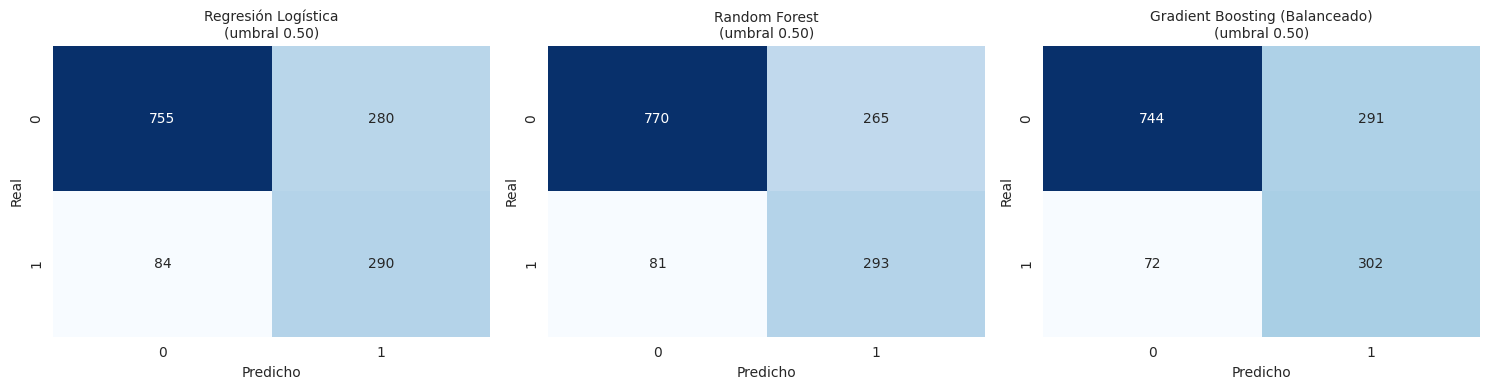

In [119]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Tomamos los primeros 3 modelos con su umbral estándar 0.5
casos = [(n.title(), p, 0.5) for n, p in list(probs_test.items())[:3]]

for ax, (nombre, prob, u) in zip(axes.flatten(), casos):
    cm = confusion_matrix(y_test, (prob >= u).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'{nombre}\n(umbral {u:.2f})', fontsize=10)
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')

plt.tight_layout()
guardar('matrices_confusion_comparacion')
plt.show()

**Análisis:** Con umbral 0.50, Gradient Boosting detecta 302 de 374 clientes en fuga (Recall 0.807) y genera 291 falsos positivos. Se observa un comportamiento predictivo muy similar entre los tres modelos principales bajo la misma configuración estándar.


###**Curvas ROC y Precision-Recall para la Evaluación Comparativa de los modelos en el Conjunto de Prueba**

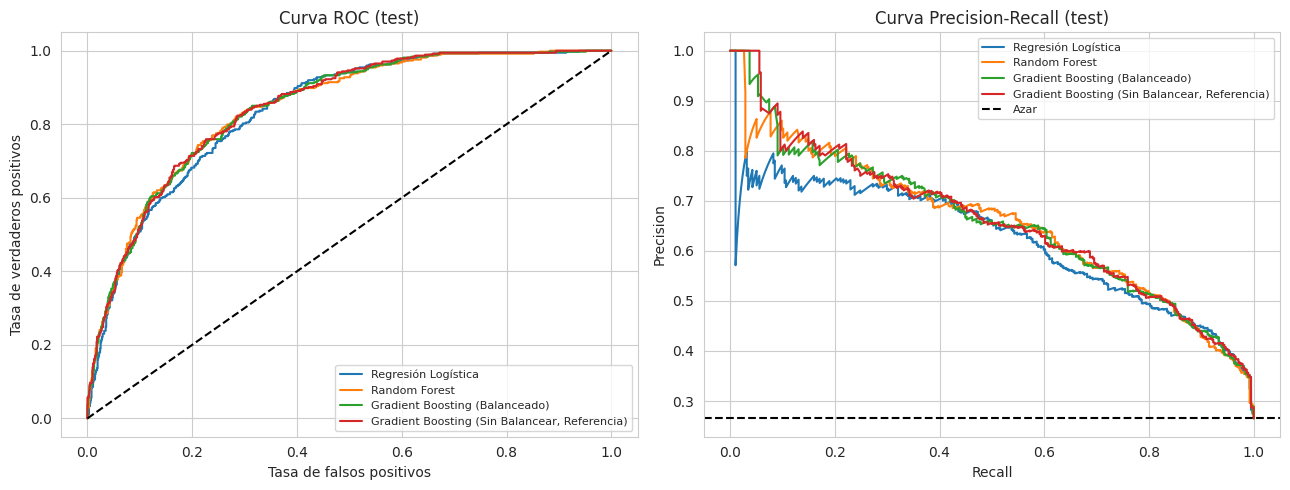

In [120]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nombre, prob in probs_test.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=nombre.title())
    pr, rc, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(rc, pr, label=nombre.title())

axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set(xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos', title='Curva ROC (test)')
axes[1].axhline(y_test.mean(), color='k', ls='--', label='Azar')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Curva Precision-Recall (test)')
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
guardar('curvas_roc_precision_recall')
plt.show()

**Análisis:** las curvas ROC son casi idénticas entre modelos, coherente con el empate en AUC. En Precision-Recall se observa que **Gradient Boosting (balanceado)** y **Random Forest** mantienen una precisión ligeramente superior en el rango de recall bajo y medio (entre 0.0 y 0.6) en comparación con la Regresión Logística, lo que los hace más robustos antes de que las falsas alarmas aumenten al exigir niveles extremos de recall.

##**12. Variables más Importantes**

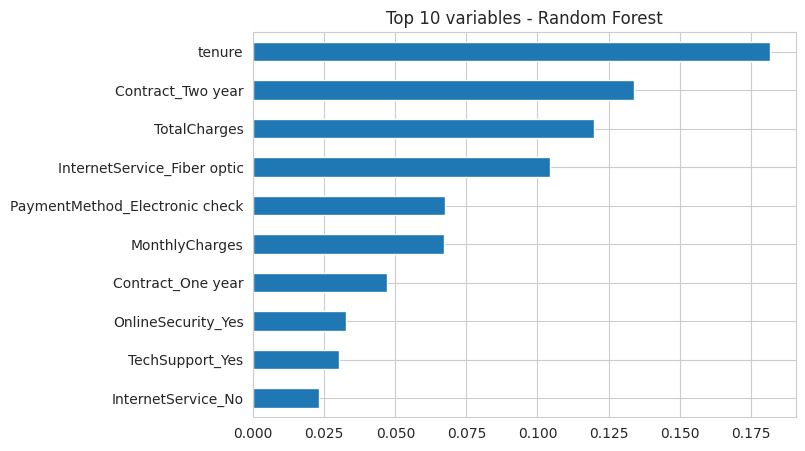

Top 10 variables - Random Forest:
tenure                            0.182
Contract_Two year                 0.134
TotalCharges                      0.120
InternetService_Fiber optic       0.104
PaymentMethod_Electronic check    0.067
MonthlyCharges                    0.067
Contract_One year                 0.047
OnlineSecurity_Yes                0.033
TechSupport_Yes                   0.030
InternetService_No                0.023



In [121]:
#Importancia según Random Forest (basada en impureza: orientativa)
imp = pd.Series(rf.feature_importances_, index=COLS_ARBOLES).sort_values(ascending=False)
plt.figure(figsize=(7, 5))
imp.head(10).sort_values().plot(kind='barh')
plt.title('Top 10 variables - Random Forest')
guardar('importancia_variables_rf')
plt.show()
print('Top 10 variables - Random Forest:')
print(imp.head(10).round(3).to_string())
print()

In [122]:
# Coeficientes de la regresión logística (variables estandarizadas; positivo = aumenta la probabilidad de churn)
coef = pd.Series(lr.named_steps['logisticregression'].coef_[0], index=COLS_LR).sort_values()
print('Variables que más AUMENTAN el churn:')
print(coef.tail(5).round(2).to_string())
print('\nVariables que más DISMINUYEN el churn:')
print(coef.head(5).round(2).to_string())

Variables que más AUMENTAN el churn:
PaymentMethod_Electronic check    0.19
MultipleLines_Yes                 0.31
StreamingTV_Yes                   0.47
StreamingMovies_Yes               0.48
InternetService_Fiber optic       1.29

Variables que más DISMINUYEN el churn:
MonthlyCharges                     -2.05
tenure                             -0.76
Contract_Two year                  -0.62
Contract_One year                  -0.30
OnlineBackup_No internet service   -0.15


Con variables estandarizadas, la antigüedad (−0.76) y los contratos de uno y dos años (−0.30, −0.62) reducen el riesgo de churn, y la fibra óptica lo aumenta (1.29).

##**13. Revisión Ética**

In [123]:
# Genera la predicción binaria final sobre el conjunto de test aplicando el umbral optimizado al mejor modelo
# Se estandariza la búsqueda a minúsculas de manera robusta y se valida la existencia del umbral optimizado
mejor_key = mejor_nombre.lower()
umbral_optimo = opt_threshold

pred_final = (probs_test[mejor_key] >= umbral_optimo).astype(int)

# Crea un DataFrame de auditoría aislando las variables demográficas en las mismas observaciones del conjunto de test
aud = df.loc[X_test.index, ['gender', 'SeniorCitizen']].copy()

# Asigna los valores reales de churn al DataFrame de auditoría
aud['real'] = y_test.values

# Asigna las predicciones optimizadas al DataFrame de auditoría
aud['pred'] = pred_final

# Define la función encargada de calcular métricas de equidad y rendimiento por cada subgrupo demográfico
def resumen_grupo(g):
    # Calcula el conteo de verdaderos positivos (TP) y falsos positivos (FP)
    tp = ((g.pred == 1) & (g.real == 1)).sum(); fp = ((g.pred == 1) & (g.real == 0)).sum()
    # Calcula el conteo de falsos negativos (FN) y verdaderos negativos (TN)
    fn = ((g.pred == 0) & (g.real == 1)).sum(); tn = ((g.pred == 0) & (g.real == 0)).sum()
    # Retorna las métricas clave del subgrupo: volumen, tasas de churn real/predicho, Recall, Precision y Tasa de Falsos Positivos
    return pd.Series({'n': len(g), '% churn real': g.real.mean() * 100, '% marcados en riesgo': g.pred.mean() * 100,
                      'Recall': tp / (tp + fn) if (tp + fn) else np.nan,
                      'Precision': tp / (tp + fp) if (tp + fp) else np.nan,
                      'Falsos positivos (%)': fp / (fp + tn) * 100 if (fp + tn) else np.nan})

# Recorre las variables demográficas de interés para realizar la auditoría de sesgo
for col in ['SeniorCitizen', 'gender']:
    # Imprime un encabezado descriptivo para la columna analizada
    print(f'--- Auditoría por {col} ---')
    # Agrupa por la variable demográfica, aplica el resumen de métricas, redondea a 2 decimales e imprime el resultado formateado
    print(aud.groupby(col).apply(resumen_grupo).round(2).to_string(), '\n')

--- Auditoría por SeniorCitizen ---
                    n  % churn real  % marcados en riesgo  Recall  Precision  Falsos positivos (%)
SeniorCitizen                                                                                     
0              1187.0         23.25                 20.64    0.56       0.63                  9.88
1               222.0         44.14                 41.89    0.66       0.70                 22.58 

--- Auditoría por gender ---
            n  % churn real  % marcados en riesgo  Recall  Precision  Falsos positivos (%)
gender                                                                                    
Female  687.0         28.09                 24.60    0.60       0.68                 10.93
Male    722.0         25.07                 23.41    0.58       0.62                 11.83 



**Auditoría:** gender se excluye del entrenamiento por criterio ético y se conserva solo para auditar. Por género los resultados son similares (mujeres: recall 0.60 y 10.93 % de falsos positivos; hombres: 0.58 y 11.83 %).

En adultos mayores (SeniorCitizen = 1) la tasa de falsos positivos es 22.58 % contra 9.88 % en el resto. Es una **disparidad de errores**, en parte explicada por su mayor churn real (44.14 % vs 23.25 %), pero no se descarta sesgo.

SeniorCitizen se mantiene como variable predictora porque separa fuertemente el churn en el EDA (41.7 % en adultos mayores contra 23.6 % en el resto), a diferencia de gender, que no muestra diferencia relevante y por eso se excluye sin costo. Como el modelo se usa para decidir a quién ofrecer un incentivo de retención, y no para negar un servicio, el perjuicio de un falso positivo es bajo. No se midió el efecto de excluirla sobre el desempeño, por lo que se deja como trabajo futuro.

**Mitigaciones posibles:** excluir SeniorCitizen, ajustar el umbral por grupo o exigir revisión humana antes de contactar.

In [124]:
# Guardar el modelo de Regresión Logística en un archivo .pkl
joblib.dump(lr, 'models/regresion_logistica.pkl')

# Guardar el modelo de Random Forest en un archivo .pkl
joblib.dump(rf, 'models/random_forest.pkl')

# Guardar el modelo de Gradient Boosting en un archivo .pkl
joblib.dump(gb, 'models/gradient_boosting.pkl')

# Listar y mostrar los archivos guardados dentro de la carpeta 'models'
print(os.listdir('models'))

['regresion_logistica.pkl', 'gradient_boosting.pkl', 'random_forest.pkl']


##**14. Aprendizaje No Supervisado: Elección de K**

In [125]:
# Escala las características seleccionadas para regresión logística para asegurar que todas tengan la misma importancia en el agrupamiento
X_cluster = StandardScaler().fit_transform(X[COLS_LR])

# Lista para guardar los resultados de métricas por cada número de clusters (k)
filas = []
# Evaluamos un rango de k entre 2 y 8
for k in range(2, 9):
    # Ajusta el modelo K-Means
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
    # Ajusta el modelo de Agrupamiento Jerárquico con enlace Ward
    ag = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X_cluster)

    # Registra inercia, Silhouette Score y el índice Davies-Bouldin para ambos algoritmos
    filas.append({'k': k, 'inercia_KM': km.inertia_,
                  'silhouette_KM': silhouette_score(X_cluster, km.labels_),
                  'silhouette_AG': silhouette_score(X_cluster, ag.labels_),
                  'DB_KM': davies_bouldin_score(X_cluster, km.labels_),
                  'DB_AG': davies_bouldin_score(X_cluster, ag.labels_)})

# Estructura los resultados en un DataFrame usando k como índice
sel_k = pd.DataFrame(filas).set_index('k')
# Calcula el porcentaje de caída de la inercia entre un valor de k y el anterior para el método del codo
sel_k['caida_inercia_%'] = -sel_k['inercia_KM'].pct_change() * 100
# Muestra la tabla de métricas en consola redondeada a 3 decimales
print(sel_k.round(3).to_string())

   inercia_KM  silhouette_KM  silhouette_AG  DB_KM  DB_AG  caida_inercia_%
k                                                                         
2  132707.713          0.353          0.353  1.048  1.048              NaN
3  116116.178          0.306          0.306  1.388  1.388           12.502
4  102703.885          0.235          0.222  1.776  1.971           11.551
5   97010.510          0.203          0.202  1.937  2.001            5.543
6   92466.310          0.206          0.207  1.984  2.082            4.684
7   89055.876          0.149          0.189  2.094  2.087            3.688
8   86069.350          0.139          0.133  2.128  2.185            3.354


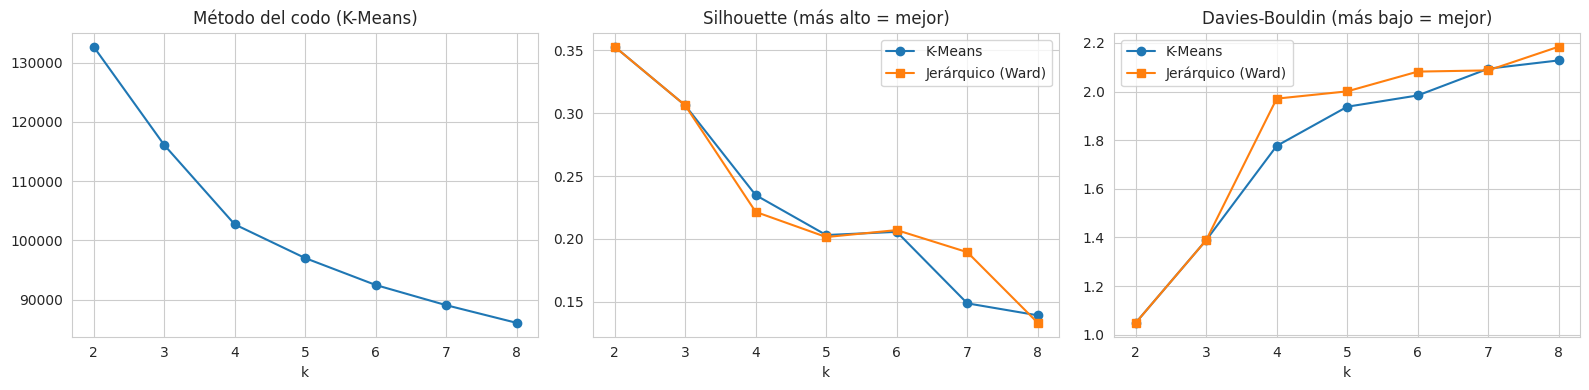

In [126]:
# Visualización gráfica de la selección del número óptimo de clusters (k)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Gráfico del método del codo (Inercia)
axes[0].plot(sel_k.index, sel_k['inercia_KM'], marker='o')
axes[0].set_title('Método del codo (K-Means)')

# 2. Gráfico de Coeficiente Silhouette
axes[1].plot(sel_k.index, sel_k['silhouette_KM'], marker='o', label='K-Means')
axes[1].plot(sel_k.index, sel_k['silhouette_AG'], marker='s', label='Jerárquico (Ward)')
axes[1].set_title('Silhouette (más alto = mejor)')
axes[1].legend()

# 3. Gráfico del Índice Davies-Bouldin
axes[2].plot(sel_k.index, sel_k['DB_KM'], marker='o', label='K-Means')
axes[2].plot(sel_k.index, sel_k['DB_AG'], marker='s', label='Jerárquico (Ward)')
axes[2].set_title('Davies-Bouldin (más bajo = mejor)')
axes[2].legend()

# Configuración común para los ejes X y distribución visual
for ax in axes:
    ax.set_xlabel('k')
plt.tight_layout()
guardar('seleccion_k_clustering')
plt.show()

**Selección de k:** k=2 obtiene el mejor silhouette (**0.353**) y Davies-Bouldin (**1.048**), pero su partición es poco útil para el negocio. El perfil con k=2 (sección 15) muestra que solo separa a los clientes **sin internet** (1.526 clientes, 7.4 % de churn), que coinciden con el segmento C3 de k=4, del resto de la cartera: un único grupo de 5.517 clientes (78 %) con 31.8 % de churn, que mezcla clientes nuevos y antiguos, con DSL y con fibra. Dentro de ese grupo, el churn de los segmentos de k=4 va de 14.9 % a 47.3 %, por lo que una sola estrategia de retención no sería adecuada.

Se elige **k=4** porque el codo muestra el último descenso relevante de inercia (**11.55 %**) y subdivide ese grupo en tres perfiles con riesgo, antigüedad y facturación claramente distintos. Se reconoce que su silhouette (**0.235** en K-Means) indica una estructura moderada a débil, por lo que la decisión se apoya en la utilidad comercial y no solo en las métricas.

##**15. Clusters Finales, Estabilidad y Perfiles**

In [127]:
# Define el número óptimo final de clusters para el análisis
K_FINAL = 4

# Entrena el modelo K-Means con k=4
km = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
# Entrena el modelo Jerárquico Aglomerativo (enlace Ward) con k=4
ag = AgglomerativeClustering(n_clusters=K_FINAL, linkage='ward').fit(X_cluster)

In [128]:
#Numera los clusters de mayor a menor tasa de churn
def reordenar(labels):
    # Calcula la tasa promedio de churn por cluster y ordena los índices de mayor a menor
    orden = pd.Series(df['Churn_num'].values).groupby(labels).mean().sort_values(ascending=False).index
    # Mapea las etiquetas originales a su nueva posición ordenada (0 = mayor churn)
    mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
    return np.array([mapa[l] for l in labels])

In [129]:
# Asigna los clusters reordenados al DataFrame principal
df['cluster_km'] = reordenar(km.labels_)
df['cluster_ag'] = reordenar(ag.labels_)

In [130]:
# Evaluación de estabilidad: compara la consistencia de K-Means frente a diferentes semillas
ari_semillas = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K_FINAL, n_init=10, random_state=s).fit(X_cluster).labels_)
                for s in range(10)]
print('ARI entre K-Means con distintas semillas (1 = idénticos): min =', round(min(ari_semillas), 3),
      '| promedio =', round(float(np.mean(ari_semillas)), 3))
print('ARI K-Means vs Jerárquico:', round(adjusted_rand_score(km.labels_, ag.labels_), 3))
print('Silhouette K-Means:', round(silhouette_score(X_cluster, km.labels_), 3),
      '| Silhouette Jerárquico:', round(silhouette_score(X_cluster, ag.labels_), 3))

ARI entre K-Means con distintas semillas (1 = idénticos): min = 0.994 | promedio = 0.999
ARI K-Means vs Jerárquico: 0.664
Silhouette K-Means: 0.235 | Silhouette Jerárquico: 0.222


**Estabilidad:** K-Means es muy estable entre semillas (con un promedio de ARI = **0.999**) y moderadamente consistente con el agrupamiento jerárquico (ARI = **0.664**), lo que respalda la existencia de los segmentos, aunque con un silhouette bajo.

In [131]:
# Reducción de dimensionalidad con PCA únicamente con fines de visualización espacial
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X_cluster)
print('Varianza explicada por los 2 componentes:', round(pca.explained_variance_ratio_.sum() * 100, 1), '%')

Varianza explicada por los 2 componentes: 45.5 %


Los dos primeros componentes explican solo el **45.5%** de la varianza, por lo que el solapamiento visual en el gráfico es de esperarse. Se usan solo para visualizar, no para segmentar.

**Limitación:** K-Means usa distancia euclidiana sobre variables dummy.

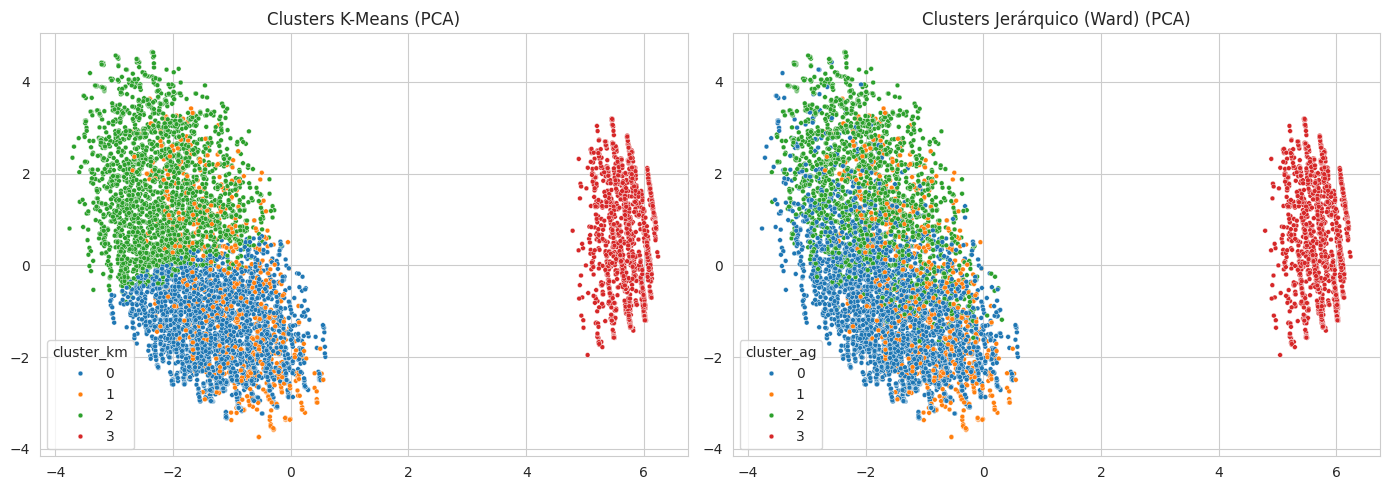

In [132]:
# Gráficos de dispersión de las dos primeras componentes principales coloreados por cluster
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, titulo in zip(axes, ['cluster_km', 'cluster_ag'], ['K-Means', 'Jerárquico (Ward)']):
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df[col], palette='tab10', s=12, ax=ax)
    ax.set_title(f'Clusters {titulo} (PCA)')
plt.tight_layout()
guardar('visualizacion_clusters_pca')
plt.show()

In [133]:
# Entrenar modelo KMeans con 2 clusters sobre los datos X_cluster
km2 = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)

# Asignar a cada fila del DataFrame la etiqueta del cluster correspondiente
df['cluster_k2'] = km2.labels_

# Calcular e imprimir la caracterización/perfil de los 2 clusters
print(perfil('cluster_k2').to_string())

# Eliminar la columna temporal de clusters para mantener limpio el DataFrame
df.drop(columns='cluster_k2', inplace=True)

            n_clientes  tenure  MonthlyCharges  tasa_churn_%  %_mes_a_mes  %_fibra  %_sin_internet  %_senior  %_cheque_electr  servicios_extra
cluster_k2                                                                                                                                    
0                 5517    32.9            76.8          31.8         60.7     56.1             0.0      19.8             40.7              2.6
1                 1526    30.5            21.1           7.4         34.3      0.0           100.0       3.4              8.0              0.0


In [134]:
# Caracterización y perfilamiento detallado de los segmentos resultantes
servicios = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
def perfil(col):
    g = df.groupby(col)
    return pd.DataFrame({
        'n_clientes': g.size(),
        'tenure': g['tenure'].mean(),
        'MonthlyCharges': g['MonthlyCharges'].mean(),
        'tasa_churn_%': g['Churn_num'].mean() * 100,
        '%_mes_a_mes': g['Contract'].apply(lambda s: (s == 'Month-to-month').mean() * 100),
        '%_fibra': g['InternetService'].apply(lambda s: (s == 'Fiber optic').mean() * 100),
        '%_sin_internet': g['InternetService'].apply(lambda s: (s == 'No').mean() * 100),
        '%_senior': g['SeniorCitizen'].mean() * 100,
        '%_cheque_electr': g['PaymentMethod'].apply(lambda s: (s == 'Electronic check').mean() * 100),
        'servicios_extra': df[servicios].eq('Yes').sum(axis=1).groupby(df[col]).mean(),
    }).round(1)

# Despliega los perfiles promedio por segmento para ambos métodos
print('\n=== Perfil K-Means ===')
print(perfil('cluster_km').to_string())
print('\n=== Perfil Jerárquico (Ward) ===')
print(perfil('cluster_ag').to_string())


=== Perfil K-Means ===
            n_clientes  tenure  MonthlyCharges  tasa_churn_%  %_mes_a_mes  %_fibra  %_sin_internet  %_senior  %_cheque_electr  servicios_extra
cluster_km                                                                                                                                    
0                 2670    16.2            74.2          47.3         92.7     66.7             0.0      22.5             55.2              1.5
1                  682    31.7            42.0          24.9         55.1      0.0             0.0      15.2             33.1              2.6
2                 2165    53.8            91.1          14.9         23.0     60.8             0.0      17.8             25.1              4.0
3                 1526    30.5            21.1           7.4         34.3      0.0           100.0       3.4              8.0              0.0

=== Perfil Jerárquico (Ward) ===
            n_clientes  tenure  MonthlyCharges  tasa_churn_%  %_mes_a_mes  %_fibra  

**Segmentos (K-Means, k=4):** **C0** es el de mayor riesgo (**47.3%** de churn): clientes nuevos, contrato mes a mes, fibra óptica y pocos servicios adicionales contratados (1,5 en promedio). **C1**: clientes de riesgo moderado (**24.9%** de churn) que utilizan servicio DSL y tienen cargos mensuales intermedios. **C2**: clientes antiguos de alta facturación y menor riesgo (**14.9%** de churn) con múltiples servicios agregados. **C3**: clientes sin servicio de internet y de bajo costo mensual, con el riesgo más bajo de todos (**7.4%** de churn). Se usó el churn solo para perfilar, no para construir los clusters.

##**16. Conclusión**

**1. Diagnóstico:** la antigüedad y el tipo de contrato son los factores que más separan al cliente que se queda del que se va. El riesgo se concentra en contratos mes a mes, fibra óptica y pago con cheque electrónico.

**2. Modelo:** **Gradient Boosting (balanceado)** obtiene un ROC-AUC de **0.845** en test. Los tres modelos rinden de forma muy similar (dentro del rango 0.845 - 0.848), por lo que la elección se apoya en el **Average Precision en validación cruzada (0.663)** y la consistencia en el manejo de desbalance. Bajo el umbral estándar de **0.50**, alcanza un recall de **80.7%** para el modelo seleccionado.

**3. Negocio y segmentación:** Se recomienda priorizar las estrategias de retención enfocadas en el segmento de mayor riesgo (C0) buscando la conversión a contratos de plazo fijo, programas de fidelización estructurados y monitoreos de bajo costo.

**4. Ética y límites:** no hay diferencias relevantes de comportamiento predictivo por género (recall simétrico de ~0.59), pero sí una disparidad notable en la tasa de falsos positivos de adultos mayores (22.58% vs 9.88%) que requiere mitigación activa. La segmentación de clientes mediante clustering tiene una estructura con coeficientes moderados.

Desarrollo completo y justificaciones: ver informe técnico (`README.md`).
